In [5]:
library(dplyr)
library(Seurat)
library(patchwork)
library(DoubletFinder)
library(SingleR)
library(CellChat)
library(SingleCellExperiment)
library(SeuratWrappers)
library(devtools)
library(celldex)
library(ggplot2)
library(Matrix)
library(RColorBrewer)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Warning message:
“package ‘Seurat’ was built under R version 4.3.3”
Loading required package: SeuratObject

Warning message:
“package ‘SeuratObject’ was built under R version 4.3.3”
Loading required package: sp

Warning message:
“package ‘sp’ was built under R version 4.3.3”

Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘matrixStats’


The following object is masked from ‘package:dplyr’:

    count



Attaching package: ‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, c

In [2]:
library(future)
plan(sequential)


Attaching package: ‘future’


The following objects are masked from ‘package:igraph’:

    %->%, %<-%




In [ ]:
counts_df <- read.csv("Data/Imaging_data/S1R1/cell_by_gene.csv", row.names = 1, check.names = FALSE)

In [ ]:
counts_mat <- as(as.matrix(counts_df), "dgCMatrix")

In [ ]:
meta_df <- read.csv("Data/Imaging_data/S1R1/cell_metadata.csv", row.names = 1)

In [ ]:
dim(counts_mat)

[1] 78329   649

In [ ]:
dim(meta_df)

[1] 78329     8

### Transpose the matrix where column whould be cell and rows genes

In [ ]:
counts_mat_t <- t(counts_mat)

In [ ]:
dim(counts_mat_t)

[1]   649 78329

In [ ]:
dim(meta_df)

[1] 78329     8

In [ ]:
S1R1 <- CreateSeuratObject( 
  counts = counts_mat_t ,    # raw counts
  meta.data = meta_df, # data frame with same rownames as columns of counts_matrix
  project = "S1R1"
)

In [ ]:
colnames(meta_df)


[1] "fov"      "volume"   "center_x" "center_y" "min_x"    "max_x"    "min_y"   
[8] "max_y"

In [ ]:
# Extract spatial coordinates from metadata
spatial_coords <- meta_df[, c("center_x", "center_y")]

# Rename columns to match Seurat expectations
colnames(spatial_coords) <- c("spatial_1", "spatial_2")

# Add as a DimReduc object to Seurat
S1R1[["spatial"]] <- CreateDimReducObject(
  embeddings = as.matrix(spatial_coords),
  key = "spatial_",
  assay = DefaultAssay(S1R1)
)

In [ ]:
saveRDS(S1R1, file = "Jupyter_Notebook_R/S1R1/S1R1.rds")


In [ ]:
S1R1

An object of class Seurat 
649 features across 78329 samples within 1 assay 
Active assay: RNA (649 features, 0 variable features)
 1 layer present: counts
 1 dimensional reduction calculated: spatial

### Filter the amount of the cell to return high-quality cells more than 100

In [ ]:
S1R1_Q <- subset(S1R1, subset = nCount_RNA > 100)


In [ ]:
S1R1_Q

An object of class Seurat 
649 features across 67624 samples within 1 assay 
Active assay: RNA (649 features, 0 variable features)
 1 layer present: counts
 1 dimensional reduction calculated: spatial

In [ ]:
S1R1_Q <- NormalizeData(S1R1_Q, normalization.method="LogNormalize", scale.factor=1e4)

Normalizing layer: counts

Warning message:
“package ‘Seurat’ was built under R version 4.3.3”
Loading required package: SeuratObject

Warning message:
“package ‘SeuratObject’ was built under R version 4.3.3”
Loading required package: sp

Warning message:
“package ‘sp’ was built under R version 4.3.3”

Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Warning message:
“package ‘Seurat’ was built under R version 4.3.3”
Loading required package: SeuratObject

Warning message:
“package ‘SeuratObject’ was built under R version 4.3.3”
Loading required package: sp

Warning message:
“package ‘sp’ was built under R version 4.3.3”

Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Warning message:
“package ‘Seurat’ was built under R version 4.3.3”
Loading required package: SeuratObject

Warning message:
“package ‘SeuratObject’ was built under R version 4.3.3”
Loading required 

In [ ]:
S1R1_Q <- FindVariableFeatures(S1R1_Q, assay = "RNA")

Finding variable features for layer counts



In [ ]:
S1R1_Q <- ScaleData(S1R1_Q, assay = "RNA", features = VariableFeatures(S1R1_Q))


Centering and scaling data matrix



In [ ]:
S1R1_Q <- RunPCA(S1R1_Q, npcs = 30)

PC_ 1 
Positive:  S1pr1, Mertk, Flt1, Adgrf5, Cldn5, Axl, Fzd6, Adgrl4, Pdgfrb, Tek 
	   Slco1a4, Fn1, Gramd3, Kdr, Tie1, Emcn, Aqp4, Gpr37l1, Gfap, Ntsr2 
	   Gpr146, Fzd2, Fgfr3, Gpr4, Adgrg1, Atp13a5, Flt4, Ednrb, Mlc1, Sox9 
Negative:  Syt4, Grm5, Grin2b, Gpr158, Cx3cl1, Gabbr2, Celsr2, Epha6, Lmtk2, Ephb6 
	   Ackr1, Gpr162, Grm1, Gpr85, Adgrb1, Chrm3, Epha7, Gpr22, Baiap2, Grm7 
	   Gpr61, Gpr75, Gpr26, Celsr3, Fzd3, Ntrk3, Cnr1, Epha10, Adgrl1, Ephb2 
PC_ 2 
Positive:  Cldn5, Flt1, Adgrf5, Arhgap29, Cxcl12, Fn1, Tek, Adgrl4, Slco1a4, Kdr 
	   Tie1, Emcn, Fzd6, Gpr4, Adgra2, Flt4, Gper1, Anxa11, Gprc5c, S1pr3 
	   Tbxa2r, Epha2, Abcc9, Nrp1, Baiap2, Ccrl2, Kcnj8, Myh11, Gpr182, Lmod1 
Negative:  Gjc3, Olig1, Fgfr2, Plxnb3, Gprc5b, Sox8, Erbb3, S1pr5, Ddr1, Gpr62 
	   Gramd3, Gpr37l1, Erbb4, Ednrb, Ephb1, Lpar1, Aqp4, Ntsr2, Grm3, Fgfr3 
	   Timp4, Aldh1l1, Slc25a18, Ntrk2, Sema4d, Sox9, Tyro3, Gabbr1, Adora1, Fzd9 
PC_ 3 
Positive:  P2yr13, Cx3cr1, Selplg, Csf1r, P2ry6, Gpr34, P2

In [ ]:
S1R1_Q <- FindNeighbors(S1R1_Q,reduction = "pca", dims = 1:30)


Computing nearest neighbor graph

Computing SNN



In [ ]:
S1R1_Q <- FindClusters(S1R1_Q, resolution = 0.3)


Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 67624
Number of edges: 2561790

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9578
Number of communities: 20
Elapsed time: 12 seconds


In [ ]:
S1R1_Q <- RunUMAP(S1R1_Q, dims = 1:20)


Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
22:29:58 UMAP embedding parameters a = 0.9922 b = 1.112

22:29:58 Read 67624 rows and found 20 numeric columns

22:29:58 Using Annoy for neighbor search, n_neighbors = 30

22:29:58 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

22:30:02 Writing NN index file to temp file /tmp/RtmpI2Fh9J/filed6d206d07b317

22:30:02 Searching Annoy index using 1 thread, search_k = 3000

22:30:21 Annoy recall = 100%

22:30:22 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors

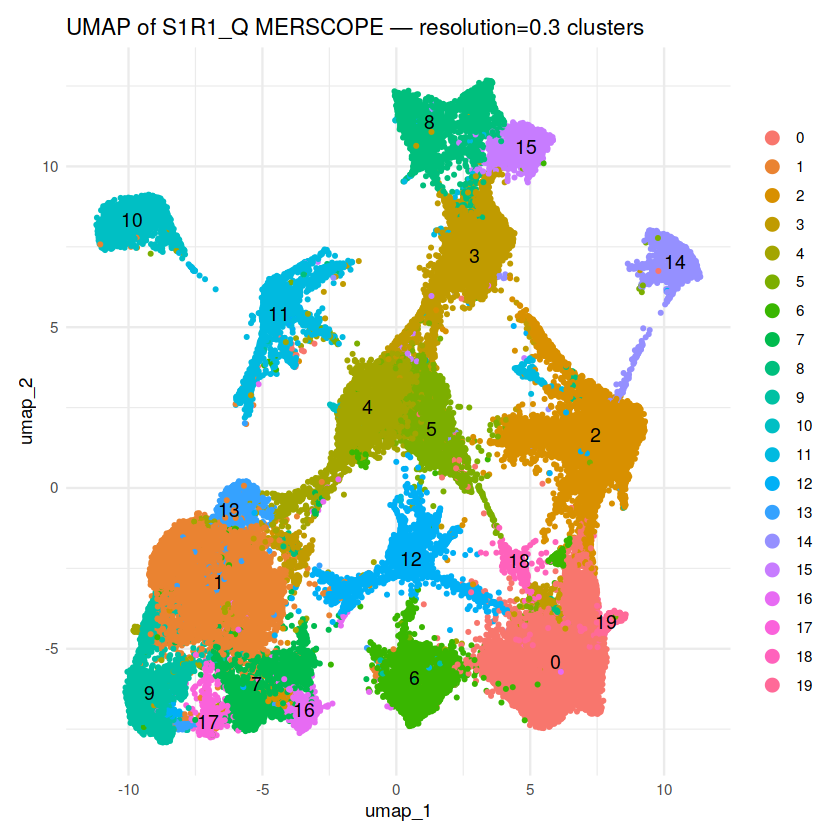

In [ ]:
# Assuming you’ve already run PCA, FindNeighbors, FindClusters, and RunUMAP on `so`:
DimPlot(S1R1_Q, reduction = "umap", label = TRUE, pt.size = 0.5) +
  ggtitle("UMAP of S1R1_Q MERSCOPE — resolution=0.3 clusters") +
  theme_minimal()

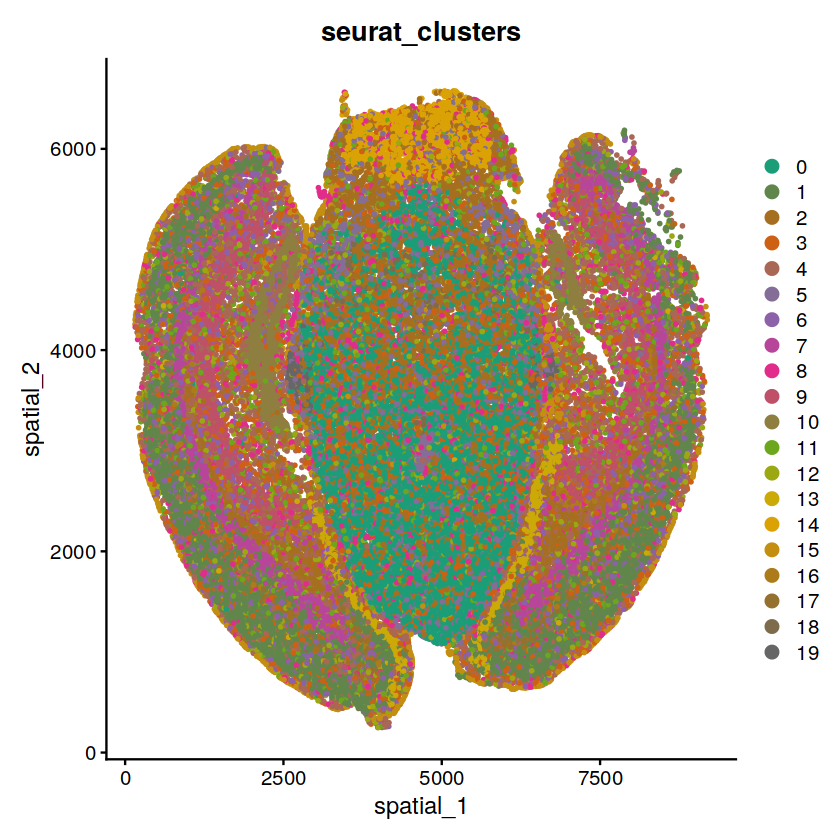

In [ ]:
num_clusters <- length(unique(S1R1_Q$seurat_clusters))
my_colors <- colorRampPalette(brewer.pal(8, "Dark2"))(num_clusters)

DimPlot(S1R1_Q, reduction = "spatial", group.by = "seurat_clusters", 
        pt.size = 0.4, cols = my_colors)

In [ ]:
saveRDS(S1R1_Q, file = "Jupyter_Notebook_R/S1R1/S1R1_MERSCOPE_Normalized_Seurat_R.rds")


In [ ]:
S1R1_Q <- readRDS("Jupyter_Notebook_R/S1R1/S1R1_MERSCOPE_Normalized_Seurat_R.rds")

In [ ]:
markers <- FindAllMarkers(S1R1_Q, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.25)
head(markers)

Calculating cluster 0

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This 

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
Flt3,0,2.221885,0.728,0.216,0,0,Flt3
Grm4,0,1.939736,0.917,0.413,0,0,Grm4
Alk,0,2.310460,0.663,0.165,0,0,Alk
Gpr153,0,1.745523,0.757,0.267,0,0,Gpr153
Amigo2,0,2.554326,0.640,0.150,0,0,Amigo2
Htr2c,0,2.701514,0.653,0.168,0,0,Htr2c


In [ ]:
top_markers <- markers %>%
  group_by(cluster) %>%
  arrange(desc(avg_log2FC), desc(pct.1)) %>%
  slice_head(n = 10)

In [ ]:
top_markers

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,3.963618,0.412,0.035,0,0,Gpr139
0,3.412057,0.556,0.079,0,0,Lgr5
0,3.354018,0.411,0.064,0,0,Tacr1
0,3.242785,0.293,0.037,0,0,Dgkk
0,3.025243,0.678,0.285,0,0,Slc17a6
0,2.944803,0.595,0.176,0,0,Slc32a1
0,2.893026,0.387,0.065,0,0,Epha8
0,2.848718,0.303,0.074,0,0,Tacr3
0,2.827462,0.611,0.132,0,0,Oprm1


In [ ]:
write.csv(top_markers, file = "top_markers_S1R1.csv", row.names = FALSE)

Warning message:
“The `slot` argument of `FetchData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


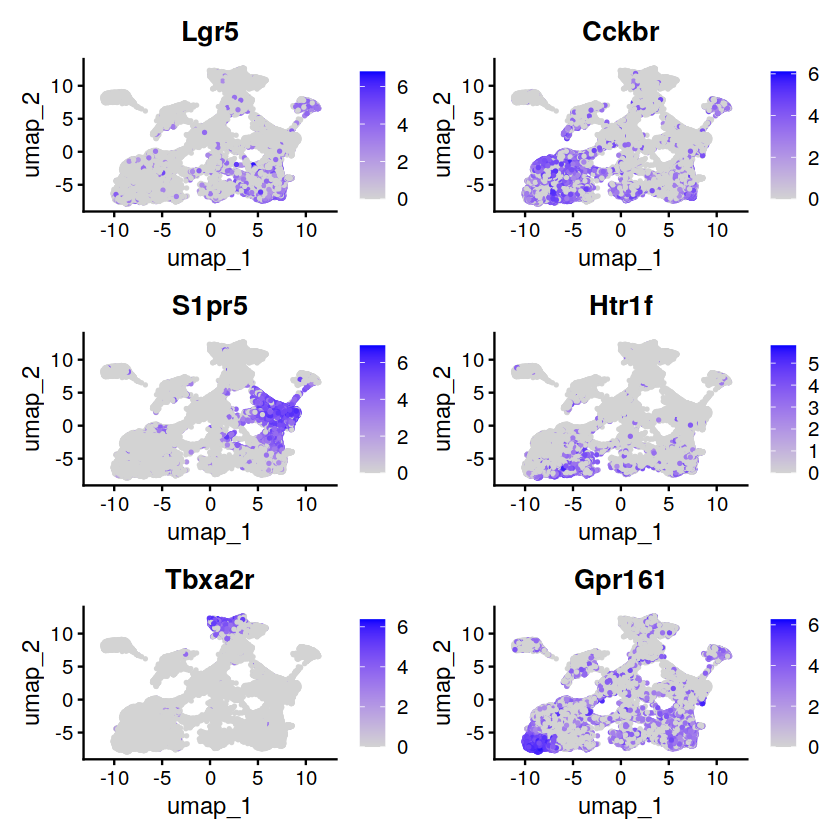

In [ ]:
FeaturePlot(S1R1_Q, features = c("Lgr5", "Cckbr", "S1pr5","Htr1f","Tbxa2r","Gpr161"), pt.size = 0.3)

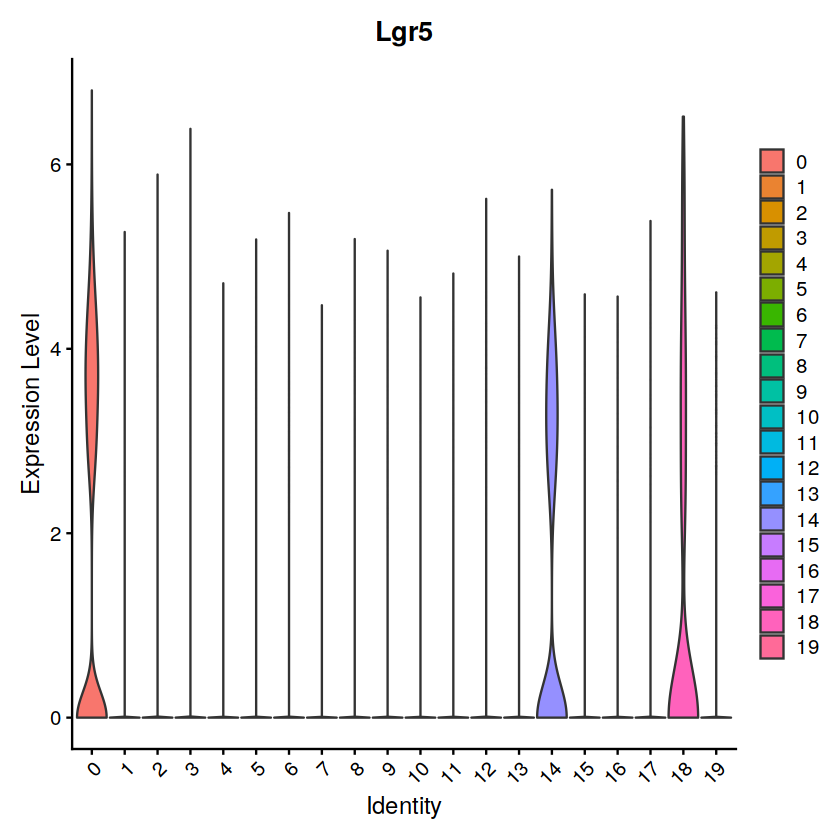

In [ ]:
VlnPlot(S1R1_Q, features = c("Lgr5"), group.by = "seurat_clusters", pt.size = 0)

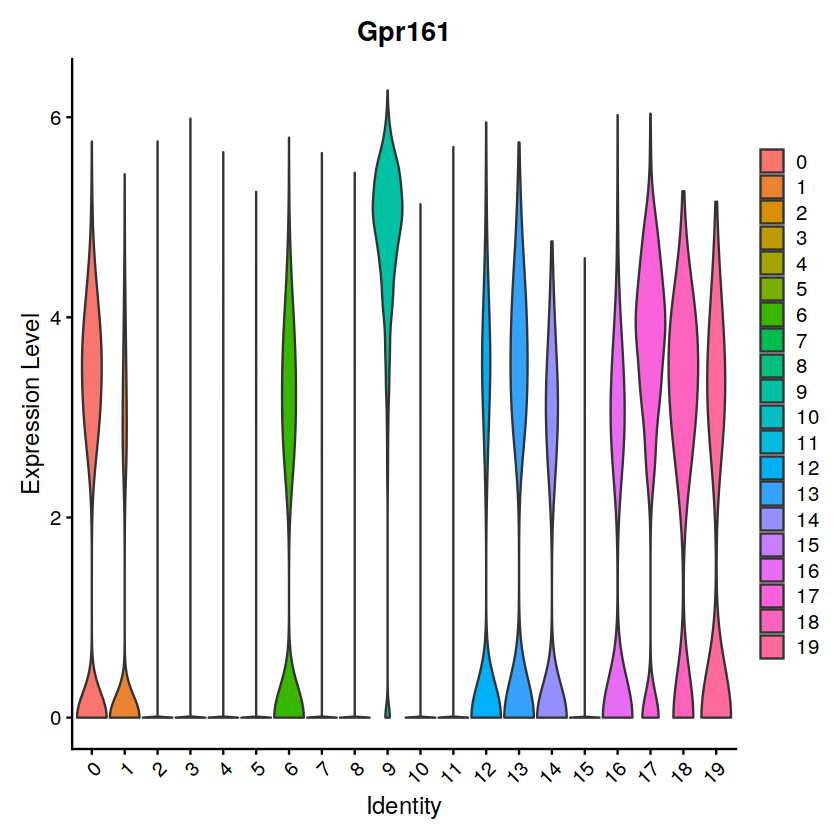

In [ ]:
VlnPlot(S1R1_Q, features = c("Gpr161"), group.by = "seurat_clusters", pt.size = 0)

### Automation Annotation Cell Types

### Using the MouseRNAseqData (celldex)

In [ ]:
S1R1_Q_Automatic <-S1R1_Q

In [ ]:
ref <- MouseRNAseqData()

see ?celldex and browseVignettes('celldex') for documentation

downloading 1 resources

retrieving 1 resource

loading from cache

see ?celldex and browseVignettes('celldex') for documentation

downloading 1 resources

retrieving 1 resource

loading from cache



In [ ]:
singler_pred <- SingleR(
  test = GetAssayData(S1R1_Q_Automatic, slot = "data"),   # normalized log1p expression
  ref = ref,
  labels = ref$label.main
)

In [ ]:
S1R1_Q_Automatic$SingleR <- singler_pred$labels

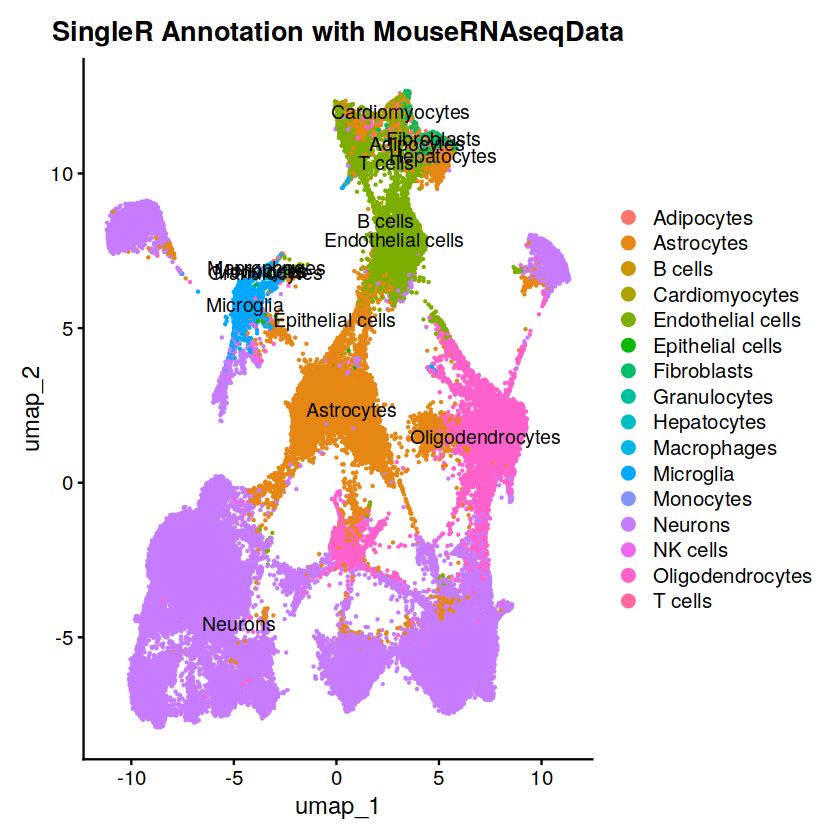

In [ ]:
DimPlot(
  S1R1_Q_Automatic,
  group.by = "SingleR",
  label = TRUE,
  reduction = "umap"
) +
  ggtitle("Automatic Annotation\nwith MouseRNAseqData reference")


In [ ]:
saveRDS(S1R1_Q_Automatic, file = "Jupyter_Notebook_R/S1R1/S1R1_Q_Automatic_R.rds")


### Manual Annotation Cell Types

In [ ]:
library(readxl)
library(dplyr)

### Read the full marker list and do the left join with the CellMarker mouse Brain list to return the hit cell type per cluster

In [ ]:
cellmarker_list <- read_excel("Cell_marker_Mouse.xlsx", sheet = 1)

In [ ]:
glimpse(cellmarker_list)

Rows: 35,197
Columns: 20
$ species           <chr> "Mouse", "Mouse", "Mouse", "Mouse", "Mouse", "Mouse"…
$ tissue_class      <chr> "Abdomen", "Abdomen", "Abdomen", "Abdomen", "Abdomen…
$ tissue_type       <chr> "Muscle", "Muscle", "Muscle", "Muscle", "Muscle", "M…
$ uberonongology_id <chr> "UBERON_0001630", "UBERON_0001630", "UBERON_0001630"…
$ cancer_type       <chr> "Normal", "Normal", "Normal", "Normal", "Normal", "N…
$ cell_type         <chr> "Normal cell", "Normal cell", "Normal cell", "Normal…
$ cell_name         <chr> "Fibro-adipogenic progenitor cell", "Myoblast", "Mus…
$ cellontology_id   <chr> NA, "CL_0000056", "CL_0000514", "CL_0000187", "CL_00…
$ marker            <chr> "Wisp1", "Myod1", "Myf5", "Ckm", "Acta1", "Ccl21a", …
$ Symbol            <chr> "Ccn4", "Myod1", "Myf5", "Ckm", "Acta1", "Ccl21a", "…
$ GeneID            <chr> "22402", "17927", "17877", "12715", "11459", "18829"…
$ Genetype          <chr> "protein_coding", "protein_coding", "protein_coding"…
$ Genename     

In [ ]:
Top_marker <- read.csv("top_markers_S1R1.csv", stringsAsFactors=FALSE)

### Export only the lines of brain tissue 

In [ ]:
cm_brain <- cellmarker_list %>%
  filter(grepl("brain", tissue_type, ignore.case = TRUE))

In [ ]:
table(cm_brain$tissue_type)


     Blood brain barrier                    Brain         Dorsal forebrain 
                       1                     7526                        4 
         Embryonic brain Hypothalamic brain slice                 Midbrain 
                      28                       14                       13 

In [ ]:
cm_brain

species,tissue_class,tissue_type,uberonongology_id,cancer_type,cell_type,cell_name,cellontology_id,marker,Symbol,GeneID,Genetype,Genename,UNIPROTID,technology_seq,marker_source,PMID,Title,journal,year
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<dbl>
Mouse,Brain,Brain,UBERON_0000955,Normal,Normal cell,Purkinje cell,CL_0000121,PEP-19,NA,NA,NA,NA,NA,NA,Experiment,2298941,Olivocerebellar fiber maturation in normal and lurcher mutant mice: defective development in lurcher.,The Journal of comparative neurology,1990
Mouse,Brain,Brain,UBERON_0000955,Normal,Normal cell,Astrocyte,CL_0000127,Glial fibrillary acidic protein,NA,NA,NA,NA,NA,NA,Experiment,11455251,Differentiation of transplanted bone marrow cells in the adult mouse brain.,Transplantation,2001
Mouse,Brain,Brain,UBERON_0000955,Normal,Normal cell,Oligodendrocyte,CL_0000128,Carbonate dehydratase II,NA,NA,NA,NA,NA,NA,Experiment,11455251,Differentiation of transplanted bone marrow cells in the adult mouse brain.,Transplantation,2001
Mouse,Brain,Brain,UBERON_0000955,Normal,Normal cell,Astrocyte,CL_0000127,Neuron-specific enolase,NA,NA,NA,NA,NA,NA,Experiment,11455251,Differentiation of transplanted bone marrow cells in the adult mouse brain.,Transplantation,2001
Mouse,Brain,Brain,UBERON_0000955,Normal,Normal cell,Microglial cell,CL_0000129,Ionized calcium-binding adapter molecule 1,NA,NA,NA,NA,NA,NA,Experiment,11455251,Differentiation of transplanted bone marrow cells in the adult mouse brain.,Transplantation,2001
Mouse,Brain,Brain,UBERON_0000955,Normal,Normal cell,Pericyte,CL_0000669,Rgs5,Rgs5,19737,protein_coding,regulator of G-protein signaling 5,A0A0A6YWD0,NA,Experiment,12598306,Transcription profiling of platelet-derived growth factor-B-deficient mouse embryos identifies RGS5 as a novel marker for pericytes and vascular smooth muscle cells.,The American journal of pathology,2003
Mouse,Brain,Brain,UBERON_0000955,Normal,Normal cell,Pericyte,CL_0000669,Rgs5,Rgs5,19737,protein_coding,regulator of G-protein signaling 5,A0A0A6YWD0,NA,Experiment,15459006,Regulator of G-protein signaling-5 induction in pericytes coincides with active vessel remodeling during neovascularization.,Blood,2004
Mouse,Brain,Brain,UBERON_0000955,Normal,Normal cell,Neural stem cell,CL_0000047,Sox2,Sox2,20674,protein_coding,SRY (sex determining region Y)-box 2,P48432,NA,Experiment,15711057,"SOX2, a persistent marker for multipotential neural stem cells derived from embryonic stem cells, the embryo or the adult.",Developmental neuroscience,2005
Mouse,Brain,Brain,UBERON_0000955,Normal,Normal cell,Neuron,CL_0000540,NeuN,Rbfox3,52897,protein_coding,"RNA binding protein, fox-1 homolog (C. elegans) 3",Q8BIF2,NA,Experiment,16650608,Methamphetamine-induced cell death: selective vulnerability in neuronal subpopulations of the striatum in mice.,Neuroscience,2006


In [ ]:
Top_marker

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>
0,3.963618,0.412,0.035,0,0,Gpr139
0,3.412057,0.556,0.079,0,0,Lgr5
0,3.354018,0.411,0.064,0,0,Tacr1
0,3.242785,0.293,0.037,0,0,Dgkk
0,3.025243,0.678,0.285,0,0,Slc17a6
0,2.944803,0.595,0.176,0,0,Slc32a1
0,2.893026,0.387,0.065,0,0,Epha8
0,2.848718,0.303,0.074,0,0,Tacr3
0,2.827462,0.611,0.132,0,0,Oprm1


In [ ]:
cm_brain <- cm_brain %>%
  select(marker, cell_name, cell_type)

In [ ]:
cm_brain

marker,cell_name,cell_type
<chr>,<chr>,<chr>
PEP-19,Purkinje cell,Normal cell
Glial fibrillary acidic protein,Astrocyte,Normal cell
Carbonate dehydratase II,Oligodendrocyte,Normal cell
Neuron-specific enolase,Astrocyte,Normal cell
Ionized calcium-binding adapter molecule 1,Microglial cell,Normal cell
Rgs5,Pericyte,Normal cell
Rgs5,Pericyte,Normal cell
Sox2,Neural stem cell,Normal cell
NeuN,Neuron,Normal cell


In [ ]:
annotated_manual <- Top_marker %>%
  left_join(cm_brain, by = c("gene" = "marker"))

Warning message in left_join(., cm_brain, by = c(gene = "marker")):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 2 of `x` matches multiple rows in `y`.
ℹ Row 66 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship = "many-to-many"` to silence this warning.”


In [ ]:
gene_hits <- annotated_manual %>%
  filter(!is.na(cell_name)) %>%
  group_by(cluster, cell_name) %>%
  summarise(
    hits = n(),
    genes = paste(sort(unique(gene)), collapse = ", ")
  ) %>%
  ungroup() %>%
  arrange(cluster, desc(hits))

`summarise()` has grouped output by 'cluster'. You can override using the `.groups` argument.


In [ ]:
gene_hits

cluster,cell_name,hits,genes
<int>,<chr>,<int>,<chr>
0,GABAergic neuron,4,"Slc17a6, Slc32a1"
0,Glutamatergic neuron,3,"Slc17a6, Slc32a1"
0,Neuron,2,"Slc32a1, Tacr3"
0,Type IC spiral ganglion neuron,2,"Lgr5, Slc17a6"
0,Excitatory neuron,1,Slc17a6
0,Glutamatergic cell,1,Slc17a6
0,Inhibitory neuron,1,Slc32a1
0,Type I spiral ganglion neuron,1,Lgr5
0,Type II spiral ganglion neuron,1,Epha8


In [ ]:
write.csv(gene_hits,
          file = "cluster_celltype_annotation_CellMarker_S1R1.csv",
          row.names = FALSE)

In [ ]:
S1R1_Q_Manual <- S1R1_Q

### We check the result in the gene_hit and depend on that we assgin the cell Type

In [ ]:
cluster_annotations <- c(
  "0" = "Neuron",
  "1" = "Neuron",
  "2" = "Oligodendrocyte",
  "3" = "Endothelial_cell",
  "4" = "Astrocyte",
  "5" = "Astrocyte",
  "6" = "Neuron",
  "7" = "Neuron",
  "8" = "Pericyte",
  "9" = "Neuron",
  "10" = "Neuron",
  "11" = "Microglial_cell",
  "12" = "Oligodendrocyte",
  "13" = "Stem_cell",
  "14" = "Astrocyte",
  "15" = "Neuron",
  "16" = "Neuron",
  "17" = "Neuron",
  "18" = "Neuron",
  "19" = "Neuron"
)

In [ ]:
S1R1_Q_Manual@meta.data$cell_type <- plyr::mapvalues(
  x = as.character(Idents(S1R1_Q_Manual)),
  from = names(cluster_annotations),
  to   = cluster_annotations
)

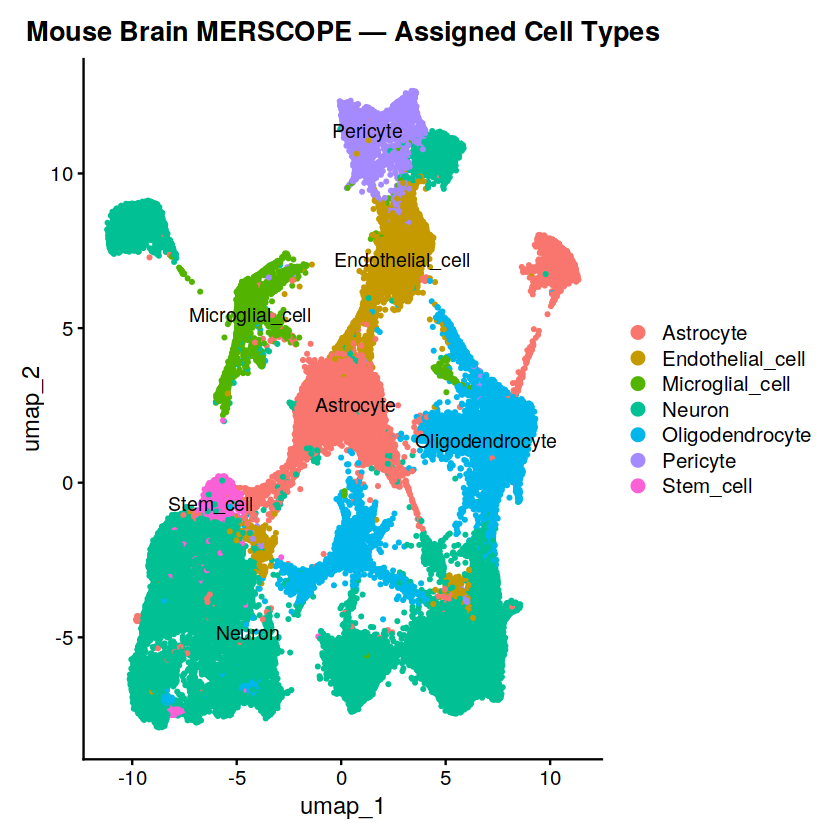

In [ ]:
DimPlot(S1R1_Q_Manual, group.by = "cell_type", label = TRUE, pt.size = 0.5) +
  ggtitle("Manual annotation by calculate \n the hiting from CellMarker list")

In [ ]:
saveRDS(S1R1_Q_Manual, file = "Jupyter_Notebook_R/S1R1/S1R1_Q_Manual_R.rds")

In [ ]:
S1R1_Q_Manual <- readRDS("Jupyter_Notebook_R/S1R1/S1R1_Q_Manual_R.rds")

### Create CSV file for counts and Meta data

In [ ]:
counts_mat <- as.data.frame(GetAssayData(S1R1_Q_Manual, assay="RNA", slot="data"))
counts_mat <- t(counts_mat)
counts_mat <- as.data.frame(counts_mat)



In [ ]:
rownames(counts_mat) <-  trimws(format(as.numeric(rownames(counts_mat)), scientific = FALSE))
print(rownames(counts_mat))


    [1] "135188247894899000572494553302156967936"
    [2] "164766962839370007979973550537325936640"
    [3] "165747897693809992277198268073374646272"
    [4] "260943245639751007414145782763065704448"
    [5] "332515239482475996124648852591334129664"
    [6] "34872120390903198197037728348483092480" 
    [7] "79348300038704799514324419873194639360" 
    [8] "112315799428971008045668110180364058624"
    [9] "210195037023346997167613430680116002816"
   [10] "225678205628490004637735047164676014080"
   [11] "337569741715169995887569907827211239424"
   [12] "101749104962864005463585996385963474944"
   [13] "113425335266016993295201444955680669696"
   [14] "12472822624716501113144480265156952064" 
   [15] "126576512189555996140148081019072806912"
   [16] "169749302336691003424649890114125692928"
   [17] "186427239098228014837478790960819208192"
   [18] "194538560122958006022956432271318450176"
   [19] "196214034770744000856245536073652895744"
   [20] "205936704942434993743549971902284955648"


In [ ]:
head(counts_mat)

,Oxgr1,Htr1a,Htr1b,Htr1d,Htr1f,Htr2a,Htr2b,Htr2c,Htr4,Htr5a,⋯,Blank-156,Blank-157,Blank-158,Blank-159,Blank-160,Blank-161,Blank-162,Blank-163,Blank-164,Blank-165
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
135188247894899000572494553302156967936,0,0,0.000000,0,0,0,0,0,0,0,⋯,0,0,0,0.000000,0,0,0,0,0,0
164766962839370007979973550537325936640,0,0,0.000000,0,0,0,0,0,0,0,⋯,0,0,0,0.000000,0,0,0,0,0,0
165747897693809992277198268073374646272,0,0,3.255696,0,0,0,0,0,0,0,⋯,0,0,0,0.000000,0,0,0,0,0,0
260943245639751007414145782763065704448,0,0,0.000000,0,0,0,0,0,0,0,⋯,0,0,0,3.526458,0,0,0,0,0,0
332515239482475996124648852591334129664,0,0,0.000000,0,0,0,0,0,0,0,⋯,0,0,0,0.000000,0,0,0,0,0,0
34872120390903198197037728348483092480,0,0,0.000000,0,0,0,0,0,0,0,⋯,0,0,0,0.000000,0,0,0,0,0,0


In [ ]:
meta <- S1R1_Q_Manual@meta.data
meta_df <- meta[, c("center_x","center_y","cell_type")]
colnames(meta_df) <- c("X","Y","cell_type")
rownames(meta_df) <-  trimws(format(as.numeric(rownames(meta_df)), scientific = FALSE))


In [ ]:
head(meta_df)

,X,Y,cell_type
,<dbl>,<dbl>,<chr>
135188247894899000572494553302156967936,156.5093,4256.962,Neuron
164766962839370007979973550537325936640,159.9653,4228.180,Pericyte
165747897693809992277198268073374646272,167.5793,4323.868,Pericyte
260943245639751007414145782763065704448,160.5593,4308.802,Neuron
332515239482475996124648852591334129664,160.6133,4296.112,Neuron
34872120390903198197037728348483092480,165.6893,4347.520,Neuron


In [ ]:
write.csv(
  counts_mat,
  file      = file.path("Jupyter_Notebook_R/S1R1/", "S1R1_R_counts.csv"),
  sep       = "\t",
  quote     = TRUE,
  col.names = NA,         # writes a blank header for row names
  row.names = TRUE
)

Warning message in write.csv(counts_mat, file = file.path("Jupyter_Notebook_R/S1R1/", :
“attempt to set 'col.names' ignored”
Warning message in write.csv(counts_mat, file = file.path("Jupyter_Notebook_R/S1R1/", :
“attempt to set 'sep' ignored”


In [ ]:
write.csv(
  meta_df,
  file      = file.path("Jupyter_Notebook_R/S1R1/", "S1R1_R_meta.csv"),
  sep       = "\t",
  quote     = TRUE,
  col.names = NA,         # writes a blank header for row names
  row.names = TRUE
)

Warning message in write.csv(meta_df, file = file.path("Jupyter_Notebook_R/S1R1/", :
“attempt to set 'col.names' ignored”
Warning message in write.csv(meta_df, file = file.path("Jupyter_Notebook_R/S1R1/", :
“attempt to set 'sep' ignored”


# ALLEN BRAIN MAP

### https://portal.brain-map.org/atlases-and-data/rnaseq/mouse-whole-cortex-and-hippocampus-smart-seq
### Mouse Whole Cortex and Hippocampus SMART-seq


In [1]:
S1R1_Q_Atlas <- readRDS("/home/akram/share/data/Image_data_vizgen/S1R1/S1R1_MERSCOPE_Normalized_Seurat_R.rds")
load("/home/akram/share/data/Image_data_vizgen/S1R1/Seurat.ss.rda")
metadata <- read.csv("/home/akram/share/data/Image_data_vizgen/S1R1/metadata_Atlas.csv",row.names = 1)

In [2]:
ls()

[1] "metadata"     "S1R1_Q_Atlas" "ss.seurat"

In [3]:
My_Marker <- read.csv("/home/akram/share/data/Image_data_vizgen/S1R1/top_markers_S1R1.csv")

In [6]:
seurat_obj <- AddMetaData(ss.seurat, metadata = metadata)

In [8]:
unique(seurat_obj@meta.data$subclass_label)

[1] "L5 PT CTX"       "L5 IT CTX"       "L4/5 IT CTX"     "L6 IT CTX"      
 [5] "L6 CT CTX"       "L5/6 NP CTX"     "Pvalb"           "Vip"            
 [9] "L2/3 IT CTX"     "Lamp5"           "Sst"             "Oligo"          
[13] "Sst Chodl"       "Sncg"            "Car3"            "Astro"          
[17] "L6b CTX"         "Endo"            "L2/3 IT PPP"     "SMC-Peri"       
[21] "Micro-PVM"       "CR"              "Meis2"           "VLMC"           
[25] "L5/6 IT TPE-ENT" "L4 RSP-ACA"      "DG"              "CA1-ProS"       
[29] "SUB-ProS"        "CA3"             "L2/3 IT RHP"     "CA2-IG-FC"      
[33] "L2/3 IT ENTl"    "L2 IT ENTl"      NA                "L3 IT ENT"      
[37] "L6b/CT ENT"      "L6 IT ENTl"      "CT SUB"          "NP PPP"         
[41] "L2 IT ENTm"      "L5 PPP"          "NP SUB"

In [9]:
Idents(seurat_obj) <- seurat_obj@meta.data$subclass_label

In [10]:
table(Idents(seurat_obj))


      L5 PT CTX       L5 IT CTX     L4/5 IT CTX       L6 IT CTX       L6 CT CTX 
           1750            3750           10854            4658            6350 
    L5/6 NP CTX           Pvalb             Vip     L2/3 IT CTX           Lamp5 
           2305            4109            6329            6003            4805 
            Sst           Oligo       Sst Chodl            Sncg            Car3 
           5511             231             282            1555            1193 
          Astro         L6b CTX            Endo     L2/3 IT PPP        SMC-Peri 
            969            2153             197            1497             133 
      Micro-PVM              CR           Meis2            VLMC L5/6 IT TPE-ENT 
            178              38             132             120             353 
     L4 RSP-ACA              DG        CA1-ProS        SUB-ProS             CA3 
            256            2474            1704             471             322 
    L2/3 IT RHP       CA2-I

In [11]:
markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.25)

Calculating cluster L5 PT CTX



Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown o

In [12]:
head(markers)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
Gm32960,0,55.84912,0.666,0.085,0,L5 PT CTX,Gm32960
3300002P13Rik,0,192.90515,0.818,0.395,0,L5 PT CTX,3300002P13Rik
Ap1s3,0,107.78614,0.565,0.152,0,L5 PT CTX,Ap1s3
Ccdc65,0,58.73445,0.885,0.477,0,L5 PT CTX,Ccdc65
Gm32810,0,61.61990,0.382,0.017,0,L5 PT CTX,Gm32810
Alox12b,0,18.15593,0.441,0.125,0,L5 PT CTX,Alox12b


In [18]:
head(My_Marker)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>
1,0,3.963618,0.412,0.035,0,0,Gpr139
2,0,3.412057,0.556,0.079,0,0,Lgr5
3,0,3.354018,0.411,0.064,0,0,Tacr1
4,0,3.242785,0.293,0.037,0,0,Dgkk
5,0,3.025243,0.678,0.285,0,0,Slc17a6
6,0,2.944803,0.595,0.176,0,0,Slc32a1


In [19]:
common_genes <- intersect(markers$gene, My_Marker$gene)
length(common_genes)
print(common_genes)

[1] 26

 [1] "Adra1d"  "Sstr4"   "Trhr"    "Slc32a1" "Hrh4"    "Chrm4"   "Mchr1"  
 [8] "Gpr62"   "Ppp1r3g" "Gfap"    "Celsr1"  "Kdr"     "Tie1"    "Flt4"   
[15] "Cysltr2" "Lmod1"   "Myh11"   "Cx3cr1"  "P2ry6"   "Selplg"  "Grm4"   
[22] "Ptgdr"   "Hcar1"   "Musk"    "Ror2"    "Met"    


In [26]:
library(dplyr)

In [21]:
# Ensure 'gene' is character type
My_Marker$gene <- as.character(My_Marker$gene)
markers$gene <- as.character(markers$gene)

In [22]:
# Group your sample markers per cluster
sample_by_cluster <- My_Marker %>%
  group_by(cluster) %>%
  summarise(sample_genes = list(gene))

In [23]:
colnames(markers)[colnames(markers) == "cluster"] <- "subclass"

In [24]:
head(markers$subclass)

[1] L5 PT CTX L5 PT CTX L5 PT CTX L5 PT CTX L5 PT CTX L5 PT CTX
42 Levels: L5 PT CTX L5 IT CTX L4/5 IT CTX L6 IT CTX L6 CT CTX ... NP SUB

In [34]:
ref_by_subclass <- markers %>%
  group_by(subclass) %>%
  summarise(ref_genes = list(gene), .groups = "drop")

In [35]:
comparison <- expand.grid(
  cluster = sample_by_cluster$cluster,
  subclass = ref_by_subclass$subclass,
  stringsAsFactors = FALSE
)


In [36]:
# Add overlap score (Jaccard index or raw count)
comparison$overlap <- mapply(function(sample_cluster, ref_subclass) {
  genes_sample <- sample_by_cluster$sample_genes[[which(sample_by_cluster$cluster == sample_cluster)]]
  genes_ref <- ref_by_subclass$ref_genes[[which(ref_by_subclass$subclass == ref_subclass)]]
  length(intersect(genes_sample, genes_ref))  # Raw overlap count
}, comparison$cluster, comparison$subclass)

In [37]:
best_match <- comparison %>%
  group_by(cluster) %>%
  top_n(1, overlap) %>%
  ungroup()

In [38]:
# Map subclass to clusters
cluster_to_subclass <- best_match$subclass
names(cluster_to_subclass) <- best_match$cluster

In [39]:
best_match %>% arrange(desc(overlap)) %>% print(n = Inf)


# A tibble: 93 × 3
   cluster subclass        overlap
     <int> <fct>             <int>
 1       3 Endo                  3
 2       8 SMC-Peri              3
 3      11 Micro-PVM             3
 4      15 VLMC                  3
 5       4 Astro                 2
 6       1 L4/5 IT CTX           1
 7      10 L4/5 IT CTX           1
 8       7 L6 CT CTX             1
 9       9 L6 CT CTX             1
10      17 L6 CT CTX             1
11      10 L5/6 NP CTX           1
12      16 L5/6 NP CTX           1
13       0 Pvalb                 1
14       6 Pvalb                 1
15      18 Pvalb                 1
16       1 Vip                   1
17       9 Vip                   1
18      13 Vip                   1
19      17 Vip                   1
20       2 Oligo                 1
21       5 Astro                 1
22      19 Meis2                 1
23       7 VLMC                  1
24       1 L5/6 IT TPE-ENT       1
25      16 L5/6 IT TPE-ENT       1
26      12 L5 PT CTX             0
2

In [40]:
# Get cluster identities of cells
cell_clusters <- Idents(S1R1_Q_Atlas)  # Named factor, names = cell names

# Map clusters to subclass
predicted_subclass_vec <- cluster_to_subclass[as.character(cell_clusters)]

# Make sure the vector is named by cell names (should already be)
names(predicted_subclass_vec) <- names(cell_clusters)  # Just to be safe

# Add to Seurat metadata
S1R1_Q_Atlas <- AddMetaData(S1R1_Q_Atlas, metadata = predicted_subclass_vec, col.name = "cell_type")


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


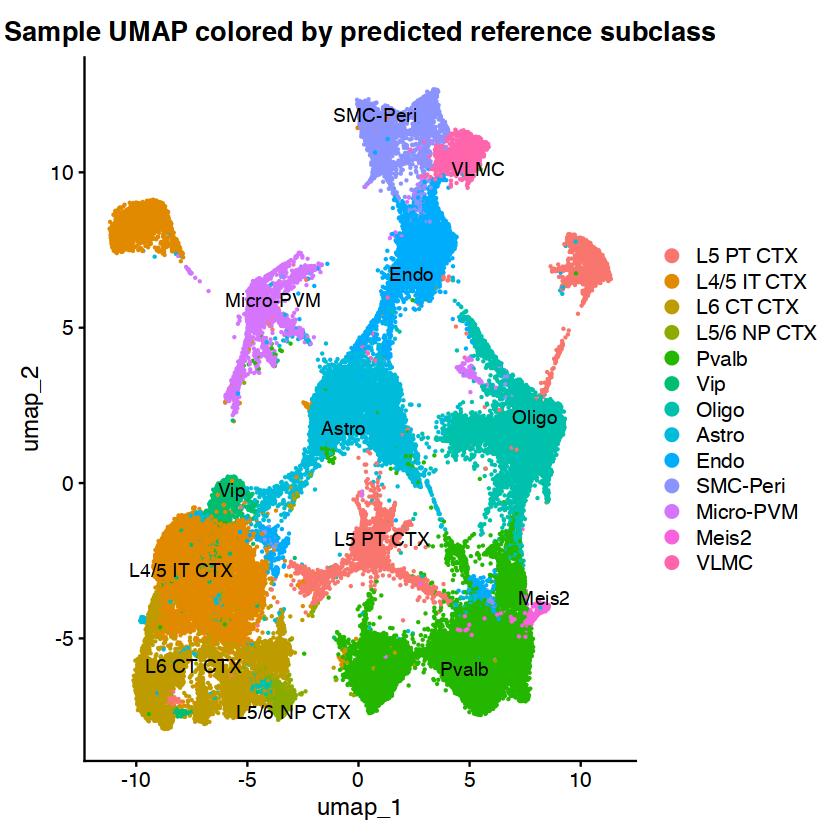

In [41]:
DimPlot(S1R1_Q_Atlas, group.by = "cell_type", label = TRUE, repel = TRUE) +
  ggtitle("Sample UMAP colored by predicted reference subclass")


### Hypergeometric and Jaccard Comparison of Cluster Markers to Allen Subclasses

In [43]:
panel    <- rownames(S1R1_Q_Atlas)
universe <- intersect(panel, rownames(seurat_obj))   # genes present in both

ref_by_subclass <- markers %>%
  filter(gene %in% universe) %>%
  group_by(subclass) %>%
  summarise(ref_genes = list(unique(gene)), .groups = "drop")

sample_by_cluster <- My_Marker %>%
  filter(gene %in% universe) %>%
  group_by(cluster) %>%
  summarise(sample_genes = list(unique(gene)), .groups = "drop")

M <- length(universe)
comparison <- expand.grid(cluster = sample_by_cluster$cluster,
                          subclass = ref_by_subclass$subclass,
                          stringsAsFactors = FALSE)

res <- t(mapply(function(cl, sc) {
  S <- sample_by_cluster$sample_genes[[match(cl, sample_by_cluster$cluster)]]
  R <- ref_by_subclass$ref_genes[[match(sc, ref_by_subclass$subclass)]]
  k <- length(intersect(S, R)); n <- length(R); N <- length(S)
  c(overlap = k,
    jaccard = k / length(union(S, R)),
    p = phyper(k - 1, n, M - n, N, lower.tail = FALSE))
}, comparison$cluster, comparison$subclass))

comparison <- cbind(comparison, res)
comparison$padj <- p.adjust(comparison$p, method = "BH")

best_match <- comparison %>%
  group_by(cluster) %>%
  arrange(p, desc(overlap), .by_group = TRUE) %>%
  dplyr::slice_head(n = 1) %>%
  ungroup()

In [44]:
old <- cluster_to_subclass[!duplicated(names(cluster_to_subclass))]
mean(old[as.character(best_match$cluster)] == best_match$subclass)

[1] 0.8

In [49]:
check <- data.frame(
  cluster = as.character(best_match$cluster),
  old_subclass = unname(old[as.character(best_match$cluster)]),
  new_subclass = as.character(best_match$subclass)
)

check$changed <- check$old_subclass != check$new_subclass
check[check$changed, ]

,cluster,old_subclass,new_subclass,changed
,<chr>,<fct>,<chr>,<lgl>
2,1,L4/5 IT CTX,L5/6 IT TPE-ENT,TRUE
13,12,L5 PT CTX,L5 IT CTX,TRUE
15,14,L5 PT CTX,L5 IT CTX,TRUE
17,16,L5/6 NP CTX,L5/6 IT TPE-ENT,TRUE


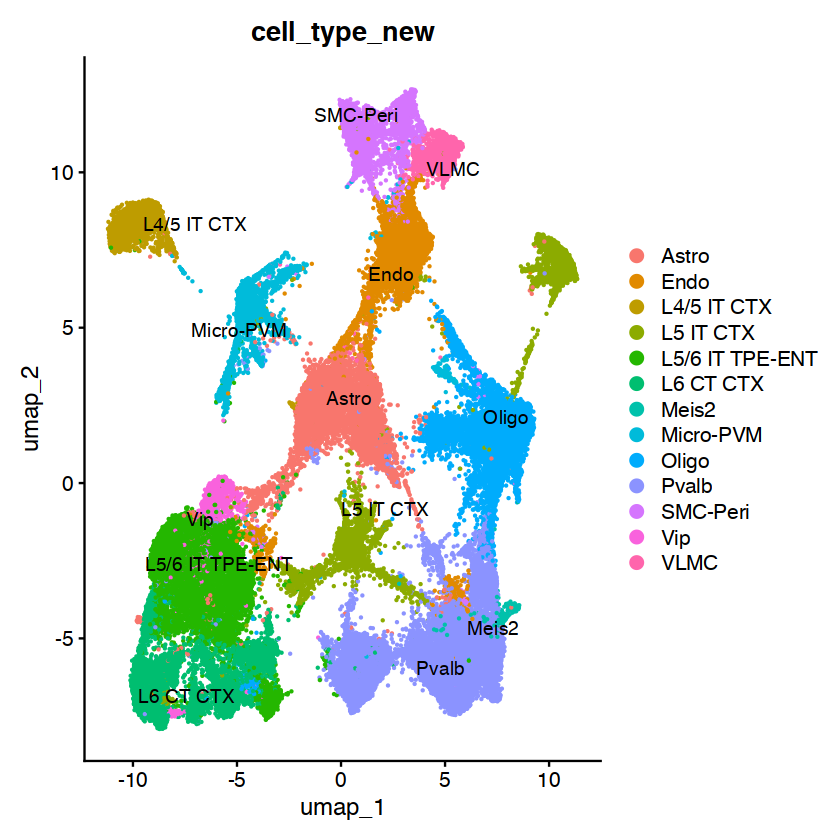

In [50]:
# Map each cluster to its new best-matching subclass
new_map <- setNames(
  as.character(best_match$subclass),
  as.character(best_match$cluster)
)

cell_clusters <- as.character(Idents(S1R1_Q_Atlas))
new_labels <- unname(new_map[cell_clusters])

# Check that every cell cluster has a matching entry
if (anyNA(new_labels)) {
  stop("Some Seurat cluster IDs do not match best_match$cluster.")
}

names(new_labels) <- names(Idents(S1R1_Q_Atlas))
S1R1_Q_Atlas <- AddMetaData(
  S1R1_Q_Atlas,
  metadata = new_labels,
  col.name = "cell_type_new"
)

DimPlot(S1R1_Q_Atlas, group.by = "cell_type_new", label = TRUE, repel = TRUE)

### Create CSV file for counts and Meta data Atlas

In [27]:
counts_mat_Atlas <- as.data.frame(GetAssayData(S1R1_Q_Atlas, assay="RNA", slot="data"))
counts_mat_Atlas <- t(counts_mat_Atlas)
counts_mat_Atlas <- as.data.frame(counts_mat_Atlas)

In [28]:
rownames(counts_mat_Atlas) <-  trimws(format(as.numeric(rownames(counts_mat_Atlas)), scientific = FALSE))
print(rownames(counts_mat_Atlas))


    [1] "135188247894899000572494553302156967936"
    [2] "164766962839370007979973550537325936640"
    [3] "165747897693809992277198268073374646272"
    [4] "260943245639751007414145782763065704448"
    [5] "332515239482475996124648852591334129664"
    [6] "34872120390903198197037728348483092480" 
    [7] "79348300038704799514324419873194639360" 
    [8] "112315799428971008045668110180364058624"
    [9] "210195037023346997167613430680116002816"
   [10] "225678205628490004637735047164676014080"
   [11] "337569741715169995887569907827211239424"
   [12] "101749104962864005463585996385963474944"
   [13] "113425335266016993295201444955680669696"
   [14] "12472822624716501113144480265156952064" 
   [15] "126576512189555996140148081019072806912"
   [16] "169749302336691003424649890114125692928"
   [17] "186427239098228014837478790960819208192"
   [18] "194538560122958006022956432271318450176"
   [19] "196214034770744000856245536073652895744"
   [20] "205936704942434993743549971902284955648"


In [29]:
meta <- S1R1_Q_Atlas@meta.data
meta_df <- meta[, c("center_x","center_y","cell_type")]
colnames(meta_df) <- c("X","Y","cell_type")
rownames(meta_df) <-  trimws(format(as.numeric(rownames(meta_df)), scientific = FALSE))

In [30]:
head(meta_df)

,X,Y,cell_type
,<dbl>,<dbl>,<fct>
135188247894899000572494553302156967936,156.5093,4256.962,VLMC
164766962839370007979973550537325936640,159.9653,4228.180,SMC-Peri
165747897693809992277198268073374646272,167.5793,4323.868,SMC-Peri
260943245639751007414145782763065704448,160.5593,4308.802,VLMC
332515239482475996124648852591334129664,160.6133,4296.112,VLMC
34872120390903198197037728348483092480,165.6893,4347.520,VLMC


In [31]:
write.csv(
  counts_mat_Atlas,
  file      = file.path("/home/akram/share/data/Image_data_vizgen/S1R1", "S1R1_R_counts_Full_Atlas.csv"),
  sep       = "\t",
  quote     = TRUE,
  col.names = NA,         # writes a blank header for row names
  row.names = TRUE
)

Warning message in write.csv(counts_mat_Atlas, file = file.path("/home/akram/share/data/Image_data_vizgen/S1R1", :
“attempt to set 'col.names' ignored”
Warning message in write.csv(counts_mat_Atlas, file = file.path("/home/akram/share/data/Image_data_vizgen/S1R1", :
“attempt to set 'sep' ignored”


In [32]:
write.csv(
  meta_df,
  file      = file.path("/home/akram/share/data/Image_data_vizgen/S1R1", "S1R1_R_meta_Full_Atlas.csv"),
  sep       = "\t",
  quote     = TRUE,
  col.names = NA,         # writes a blank header for row names
  row.names = TRUE
)


Warning message in write.csv(meta_df, file = file.path("/home/akram/share/data/Image_data_vizgen/S1R1", :
“attempt to set 'col.names' ignored”
Warning message in write.csv(meta_df, file = file.path("/home/akram/share/data/Image_data_vizgen/S1R1", :
“attempt to set 'sep' ignored”
